# Downturn LGD When Recoveries Are Scarce: Frye–Jacobs, EBA-Style Downturn Periods, Bayesian Shrinkage and Transfer Learning on Mortgage Recoveries from the 2008 Crisis to 2025

Under the internal-ratings-based approach, the loss given default (LGD) used for capital must reflect an economic downturn. That is easy to say and hard to do: a bank whose recovery data start after 2012 has never seen a downturn in house prices, and a young portfolio may have only a few dozen completed liquidations. The European Banking Authority's guidelines (EBA, 2019) describe three ways forward: estimate LGD on the defaults of an observed downturn, model the link between LGD and the economic factors that define a downturn, or add a margin when neither is possible. Frye and Jacobs (2012) offer a fourth: derive downturn LGD from the PD and the long-run LGD through a single-factor model. This notebook confronts all of them with real recoveries. A data-rich book (Fannie Mae loans of 2005–2008, with about 10,000 liquidations through the crisis) serves as the source; a data-scarce book (Freddie Mac loans of 2018–2023, with about 200 liquidations in a rising housing market) is the target that needs a downturn LGD it has never observed.

**What it does.**

1. It reads origination data and the final liquidation record of every defaulted loan in both books, computes the realised LGD (loss over balance at removal, including expenses and recoveries), and adds the mark-to-market loan-to-value at default from state house-price indices.
2. It identifies the downturn period EBA-style from national house prices and unemployment, and compares long-run average and downturn LGD on the data-rich book.
3. It tests the Frye–Jacobs LGD function against the annual LGDs and default rates the data-rich book actually produced.
4. It estimates segment LGDs on the scarce book by simple averaging and by empirical-Bayes shrinkage toward the pooled mean, and checks which predicts held-out liquidations better.
5. It fits LGD models on the rich book (fractional logit and LightGBM) and transfers them to the scarce book four ways: source only, target only, source recalibrated on the target, and pooled with up-weighted target data. It then uses the best transfer to project a downturn LGD for the scarce book under a 2008-style fall in house prices.

**Data.** Fannie Mae Single-Family Loan Performance Data (2005–2008 acquisitions) and Freddie Mac Single-Family Loan-Level Dataset (2018–2023), samples, downloaded once by hand into `data/` at the repository root; state and national house-price indices and unemployment (FRED).

**Methods.** Realised LGD from liquidation records, EBA downturn-period identification, the Frye–Jacobs LGD function, empirical-Bayes shrinkage, fractional logit regression, LightGBM, recalibration and instance-weighted transfer learning, repeated cross-validation and house-price stress scenarios.

**Key output.** LGD by year of liquidation and by type of disposition; long-run versus downturn LGD; Frye–Jacobs predictions against observed LGD; out-of-sample errors of shrinkage and of each transfer strategy on the scarce book; and the projected downturn LGD of the scarce book.

## 1. Downturn LGD in one page

**Realised LGD** of a mortgage that went through foreclosure, short sale or note sale is the loss (unpaid balance, accrued interest and expenses, minus sale proceeds and mortgage-insurance and other recoveries) divided by the balance at default.

**Why LGD rises in a downturn.** The collateral is the house: when prices fall, sale proceeds fall, more loans are under water and liquidation takes longer, so expenses grow. Defaults and losses per default rise together, as Altman, Brady, Resti and Sironi (2005) documented for corporate bonds; a capital model that uses an average LGD understates losses in exactly the years that matter.

**EBA approach.** The guidelines (EBA, 2019) ask banks to identify a downturn period from the economic factors relevant to the portfolio (for mortgages: house prices and unemployment), and to estimate LGD from defaults in that period, or to model LGD on those factors and evaluate the model in the downturn. If neither is possible, a margin of conservatism is required.

**Frye–Jacobs.** If defaults follow the Vasicek one-factor model with correlation ρ, and expected loss is consistent with a long-run PD and LGD, the LGD conditional on a default rate DR is

LGD(DR) = Φ(Φ⁻¹(DR) − *k*) / DR,  *k* = (Φ⁻¹(PD) − Φ⁻¹(PD × ELGD)) / √(1 − ρ).

LGD rises with the default rate; plugging in Basel's 99.9% default rate gives a downturn LGD from PD and ELGD alone.

**Scarce data.** With a few dozen liquidations per segment, sample averages are noisy. Shrinkage pulls each segment toward the overall mean in proportion to its noise. Transfer learning reuses a model trained where data are rich, either as is or adjusted on the scarce data.

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")


# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import zipfile
from concurrent.futures import ThreadPoolExecutor

import lightgbm as lgb
import statsmodels.api as sm
from scipy.stats import norm
from sklearn.model_selection import KFold

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

SEED = 2009
rng = np.random.default_rng(SEED)
BOOKS = {
    "Fannie Mae": ("fannie_mae", [2005, 2006, 2007, 2008]),
    "Freddie Mac": ("freddie_mac", [2018, 2019, 2020, 2021, 2022, 2023]),
}
DEFAULT_ZB = {"02", "03", "09", "15"}
ZB_NAME = {
    "02": "third-party sale",
    "03": "short sale",
    "09": "REO disposition",
    "15": "note sale",
}
JUDICIAL = {
    "CT",
    "DE",
    "FL",
    "HI",
    "IL",
    "IN",
    "IA",
    "KS",
    "KY",
    "LA",
    "ME",
    "NJ",
    "NM",
    "NY",
    "ND",
    "OH",
    "OK",
    "PA",
    "SC",
    "SD",
    "VT",
    "WI",
}
STATES = [
    "AK",
    "AL",
    "AR",
    "AZ",
    "CA",
    "CO",
    "CT",
    "DC",
    "DE",
    "FL",
    "GA",
    "HI",
    "IA",
    "ID",
    "IL",
    "IN",
    "KS",
    "KY",
    "LA",
    "MA",
    "MD",
    "ME",
    "MI",
    "MN",
    "MO",
    "MS",
    "MT",
    "NC",
    "ND",
    "NE",
    "NH",
    "NJ",
    "NM",
    "NV",
    "NY",
    "OH",
    "OK",
    "OR",
    "PA",
    "RI",
    "SC",
    "SD",
    "TN",
    "TX",
    "UT",
    "VA",
    "VT",
    "WA",
    "WI",
    "WV",
    "WY",
]
RHO_MORTGAGE, Q999 = 0.15, 0.999
N_REPEATS, TARGET_WEIGHTS = 20, [1, 5, 20, 50]

print(f"lightgbm {lgb.__version__} · run on {dt.date.today():%Y-%m-%d}")

lightgbm 4.7.0 · run on 2026-11-04


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"

## 3. Liquidations, losses and default rates

For each loan the notebook keeps its origination attributes, the first month it was 90 days past due or ended with a credit event, and, for liquidated loans, the final record: type of disposition, date, removal balance, date of last paid instalment and the reported loss. The two datasets report losses with opposite signs; both are converted to positive numbers for a loss. **LGD** is the loss over the removal balance, kept between −10% and 150% to drop a handful of reporting errors.

Annual **default rates** of each book (first 90-day delinquency or credit event during the year, over loans active and not yet defaulted at its start) feed the Frye–Jacobs test.

In [3]:
OC = [
    "fico",
    "first_pay",
    "fthb",
    "maturity",
    "msa",
    "mi_pct",
    "units",
    "occupancy",
    "cltv",
    "dti",
    "upb",
    "ltv",
    "rate",
    "channel",
    "ppm",
    "amort",
    "state",
    "prop_type",
    "zip",
    "loan_id",
    "purpose",
    "term",
    "n_borrowers",
]


def find_shared(name):
    for d in [PROJECT_DIR, *PROJECT_DIR.parents]:
        if (d / "data" / name).exists():
            return d / "data" / name
    return None


def read_vintage(zp, year, book):
    with zipfile.ZipFile(zp) as z:
        o = pd.read_csv(
            z.open(f"sample_orig_{year}.txt"),
            sep="|",
            header=None,
            usecols=range(len(OC)),
            names=OC,
            dtype=str,
        )
        fin, bad, last = [], [], []
        for ch in pd.read_csv(
            z.open(f"sample_perf_{year}.txt"),
            sep="|",
            header=None,
            usecols=[0, 1, 3, 8, 9, 12, 21, 26, 29],
            names=[
                "loan_id",
                "period",
                "dlq",
                "zb",
                "zb_date",
                "ddlpi",
                "loss",
                "removal_upb",
                "assist",
            ],
            dtype=str,
            chunksize=3_000_000,
        ):
            dlq = pd.to_numeric(
                ch["dlq"].replace({"RA": "99"}), errors="coerce"
            )
            b = ((dlq >= 3) | ch["zb"].isin(DEFAULT_ZB)) & ch["assist"].ne("F")
            bad.append(ch.loc[b, ["loan_id", "period"]])
            last.append(
                ch[["loan_id", "period"]].groupby("loan_id")["period"].max()
            )
            fin.append(ch[ch["zb"].isin(DEFAULT_ZB)])
    f = (
        pd.concat(fin)
        .drop_duplicates("loan_id", keep="last")
        .set_index("loan_id")
    )
    o = o.set_index("loan_id")
    o["first_default"] = pd.concat(bad).groupby("loan_id")["period"].min()
    o["last_period"] = pd.concat(last).groupby(level=0).max()
    o = o.join(f[["zb", "zb_date", "ddlpi", "loss", "removal_upb"]])
    o["book"], o["vintage"] = book, year
    return o.reset_index()


def load_all():
    out = []
    for book, (folder, years) in BOOKS.items():
        base = find_shared(folder)
        for y in years:
            hits = (
                [
                    h
                    for h in base.rglob(f"sample_{y}.zip")
                    if "_to_delete" not in h.parts
                ]
                if base
                else []
            )
            if hits:
                out.append(
                    read_vintage(
                        min(hits, key=lambda h: len(h.parts)), y, book
                    )
                )
    return pd.concat(out, ignore_index=True)


L = cached("mortgage_liquidations", load_all, max_age_hours=24 * 60)
for c in [
    "fico",
    "mi_pct",
    "units",
    "cltv",
    "dti",
    "upb",
    "ltv",
    "rate",
    "term",
    "n_borrowers",
    "loss",
    "removal_upb",
]:
    L[c] = pd.to_numeric(L[c], errors="coerce")
L = L[
    (L["amort"] == "FRM")
    & L["fico"].between(300, 850)
    & L["cltv"].between(1, 200)
    & L["state"].isin(STATES)
].copy()
L["orig_month"] = pd.to_datetime(
    L["first_pay"], format="%Y%m"
) - pd.DateOffset(months=2)
# positive = loss
L["loss_pos"] = np.where(L["book"] == "Fannie Mae", -L["loss"], L["loss"])
L["lgd"] = L["loss_pos"] / L["removal_upb"]
L["liq_date"] = pd.to_datetime(L["zb_date"], format="%Y%m", errors="coerce")
L["default_date"] = pd.to_datetime(
    L["ddlpi"], format="%Y%m", errors="coerce"
) + pd.DateOffset(months=3)
L["months_to_liquidate"] = (
    (L["liq_date"] - L["default_date"]).dt.days / 30.44
).clip(0, 120)
L["disposition"] = L["zb"].map(ZB_NAME)
L["judicial"] = L["state"].isin(JUDICIAL).astype(int)


def annual_dr(d):
    fd = pd.to_datetime(d["first_default"], format="%Y%m", errors="coerce")
    lp = pd.to_datetime(d["last_period"], format="%Y%m", errors="coerce")
    rows = {}
    for y in range(d["orig_month"].dt.year.min() + 1, 2026):
        start = pd.Timestamp(f"{y}-01-01")
        active = (d["orig_month"] < start) & (lp >= start) & ~(fd < start)
        dflt = active & (fd >= start) & (fd < start + pd.DateOffset(years=1))
        if active.sum() > 500:
            rows[y] = {
                "active loans": int(active.sum()),
                "defaults": int(dflt.sum()),
                "default rate": dflt.sum() / active.sum(),
            }
    return pd.DataFrame(rows).T


DR = {b: annual_dr(L[L["book"] == b]) for b in BOOKS}
LIQ = L[
    L["lgd"].between(-0.1, 1.5)
    & L["liq_date"].notna()
    & L["removal_upb"].gt(0)
].copy()
SUMMARY = LIQ.groupby("book").agg(
    liquidations=("lgd", "size"),
    mean_lgd=("lgd", "mean"),
    median_lgd=("lgd", "median"),
    balance_weighted_lgd=("loss_pos", "sum"),
    first=("liq_date", "min"),
    last=("liq_date", "max"),
)
SUMMARY["balance_weighted_lgd"] = (
    SUMMARY["balance_weighted_lgd"] / LIQ.groupby("book")["removal_upb"].sum()
)
print(f"{len(L):,} loans; {len(LIQ):,} liquidations with a usable loss")
SUMMARY.style.format({
    "liquidations": "{:,.0f}",
    "mean_lgd": "{:.1%}",
    "median_lgd": "{:.1%}",
    "balance_weighted_lgd": "{:.1%}",
})

498,119 loans; 13,522 liquidations with a usable loss


,liquidations,mean_lgd,median_lgd,balance_weighted_lgd,first,last
book,,,,,,
Fannie Mae,"13,300",46.0%,44.6%,41.8%,2005-12-01 00:00:00,2025-11-01 00:00:00
Freddie Mac,222,17.6%,10.3%,14.1%,2019-07-01 00:00:00,2025-12-01 00:00:00


## 4. Mark-to-market LTV, downturn period and long-run versus downturn LGD

**Mark-to-market LTV at default.** The combined LTV at origination is scaled by the change in the state house-price index (FHFA, quarterly) from origination to the default date. It is the single most important driver of mortgage LGD (Qi & Yang, 2009).

**Long-run average.** The EBA requires the long-run LGD to be default-weighted, which makes it heavy with crisis defaults when, as here, most defaults happened in the crisis. The notebook also reports the year-weighted average for comparison.

**Downturn period.** Following the EBA's logic, the downturn is the period in which the economic factors relevant to the portfolio were at their worst: here, the four-quarter change in the national house-price index and the level of unemployment. The notebook marks the years in which house prices were falling year over year and unemployment was above its long-run median, and compares the LGD of loans that **defaulted** in those years with the long-run average across all years (default-weighted, as the EBA requires).

In [4]:
def fetch_hpi():
    ids = {s: f"{s}STHPI" for s in STATES} | {"US": "USSTHPI", "UR": "UNRATE"}
    with ThreadPoolExecutor(6) as ex:
        got = dict(
            zip(ids, ex.map(lambda i: fred.get_series(i), ids.values()))
        )
    return pd.DataFrame({k: v.resample("MS").mean() for k, v in got.items()})


MAC = cached("fred_state_hpi_unrate", fetch_hpi, max_age_hours=24 * 30)
MAC.index = pd.to_datetime(MAC.index)
MAC = MAC.resample("MS").mean().ffill()


def lookup(frame, months, states):
    r = frame.index.get_indexer(
        pd.to_datetime(months).dt.to_period("M").dt.to_timestamp()
    )
    c = frame.columns.get_indexer(states)
    out = np.full(len(r), np.nan)
    ok = (r >= 0) & (c >= 0)
    out[ok] = frame.to_numpy()[r[ok], c[ok]]
    return out


LIQ["hpi_change"] = (
    lookup(MAC[STATES], LIQ["default_date"], LIQ["state"])
    / lookup(MAC[STATES], LIQ["orig_month"], LIQ["state"])
    - 1
)
LIQ["mtm_ltv"] = LIQ["cltv"] / (1 + LIQ["hpi_change"])
LIQ["default_year"] = LIQ["default_date"].dt.year
LIQ = LIQ.dropna(subset=["mtm_ltv"]).copy()
macro_y = pd.DataFrame({
    "house prices, 4-quarter change": (
        MAC["US"].resample("YE").last().pct_change()
    ),
    "unemployment": MAC["UR"].resample("YE").mean(),
})
macro_y.index = macro_y.index.year
macro_y["downturn"] = (macro_y["house prices, 4-quarter change"] < 0) & (
    macro_y["unemployment"] > macro_y["unemployment"].median()
)
DT_YEARS = sorted(macro_y.index[macro_y["downturn"]])
rich = LIQ[LIQ["book"] == "Fannie Mae"]
BY_YEAR = rich.groupby("default_year").agg(
    liquidations=("lgd", "size"),
    mean_lgd=("lgd", "mean"),
    mtm_ltv=("mtm_ltv", "median"),
    months_to_liquidate=("months_to_liquidate", "median"),
)
BY_YEAR = BY_YEAR.join(macro_y).join(DR["Fannie Mae"]["default rate"])
# default-weighted, as the EBA requires
LRA_LGD = rich["lgd"].mean()
yr_lgd = rich.groupby("default_year")["lgd"].agg(["mean", "size"])
# each year weighted equally
LRA_LGD_YEARS = yr_lgd[yr_lgd["size"] >= 30]["mean"].mean()
DT_LGD = rich[rich["default_year"].isin(DT_YEARS)]["lgd"].mean()
BY_DISP = (
    LIQ.groupby(["book", "disposition"])["lgd"]
    .agg(["size", "mean"])
    .unstack(0)
)
print(
    "Downturn years (falling national house prices, unemployment above"
    f" median): {DT_YEARS}"
)
print(
    f"Fannie Mae book: long-run average LGD {LRA_LGD:.1%} default-weighted,"
    f" {LRA_LGD_YEARS:.1%} year-weighted; LGD of defaults in the downturn"
    f" years {DT_LGD:.1%}"
)
display(BY_DISP.style.format("{:.3f}", na_rep=""))
BY_YEAR[BY_YEAR["liquidations"] >= 30].style.format({
    "liquidations": "{:,.0f}",
    "mean_lgd": "{:.1%}",
    "mtm_ltv": "{:.0f}",
    "months_to_liquidate": "{:.0f}",
    "house prices, 4-quarter change": "{:+.1%}",
    "unemployment": "{:.1f}",
    "default rate": "{:.2%}",
})

Downturn years (falling national house prices, unemployment above median): [2008, 2009, 2010, 2011]
Fannie Mae book: long-run average LGD 46.0% default-weighted, 39.7% year-weighted; LGD of defaults in the downturn years 48.2%


,liquidations,mean_lgd,mtm_ltv,months_to_liquidate,"house prices, 4-quarter change",unemployment,downturn,default rate
default_year,,,,,,,,
2006.000000,71,24.2%,79,6,+4.5%,4.6,False,0.48%
2007.000000,305,37.3%,80,9,-1.1%,4.6,False,0.83%
2008.000000,"1,273",47.3%,90,14,-7.2%,5.8,True,1.98%
2009.000000,"2,765",47.8%,95,13,-5.2%,9.3,True,4.37%
2010.000000,"2,625",50.5%,99,11,-1.8%,9.6,True,4.46%
2011.000000,"2,219",46.5%,104,10,-3.3%,8.9,True,3.83%
2012.000000,"1,503",43.3%,103,9,+0.6%,8.1,False,3.37%
2013.000000,735,46.5%,97,11,+4.3%,7.4,False,2.69%
2014.000000,512,44.0%,90,14,+5.1%,6.2,False,2.27%


## 5. Does Frye–Jacobs predict the downturn LGD?

The Frye–Jacobs function is evaluated with the Fannie Mae book's own long-run PD (the average of its annual default rates), its long-run LGD and Basel's mortgage correlation of 15%, then compared with the average LGD of loans that defaulted in each year, plotted against that year's default rate. At Basel's 99.9% default rate it gives the downturn LGD implied by the model.

In [5]:
def frye_jacobs(dr, pd_, elgd, rho=RHO_MORTGAGE):
    k = (norm.ppf(pd_) - norm.ppf(pd_ * elgd)) / np.sqrt(1 - rho)
    return norm.cdf(norm.ppf(dr) - k) / dr


dr_f = DR["Fannie Mae"]["default rate"]
PD_LR = dr_f.mean()
DR_999 = norm.cdf(
    (norm.ppf(PD_LR) + np.sqrt(RHO_MORTGAGE) * norm.ppf(Q999))
    / np.sqrt(1 - RHO_MORTGAGE)
)
FJ = (
    BY_YEAR[BY_YEAR["liquidations"] >= 30][["mean_lgd", "default rate"]]
    .dropna()
    .copy()
)
FJ["Frye–Jacobs LGD"] = frye_jacobs(FJ["default rate"], PD_LR, LRA_LGD)
FJ_SUM = pd.Series({
    "long-run PD": PD_LR,
    "long-run LGD": LRA_LGD,
    "99.9% default rate (Basel ρ = 15%)": DR_999,
    "Frye–Jacobs LGD at 99.9%": frye_jacobs(DR_999, PD_LR, LRA_LGD),
    "Frye–Jacobs LGD at worst observed default rate": frye_jacobs(
        dr_f.max(), PD_LR, LRA_LGD
    ),
    "observed LGD of downturn-year defaults": DT_LGD,
    "correlation of annual LGD with default rate": (
        FJ["mean_lgd"].corr(FJ["default rate"])
    ),
    "RMSE of Frye–Jacobs vs annual LGD": np.sqrt(
        ((FJ["Frye–Jacobs LGD"] - FJ["mean_lgd"]) ** 2).mean()
    ),
})
display(FJ_SUM.to_frame("value").style.format("{:.3f}"))
FJ.style.format("{:.1%}")

,value
long-run PD,0.019
long-run LGD,0.460
99.9% default rate (Basel ρ = 15%),0.169
Frye–Jacobs LGD at 99.9%,0.588
Frye–Jacobs LGD at worst observed default rate,0.479
observed LGD of downturn-year defaults,0.482
correlation of annual LGD with default rate,0.748
RMSE of Frye–Jacobs vs annual LGD,0.072


,mean_lgd,default rate,Frye–Jacobs LGD
default_year,,,
2006.000000,24.2%,0.5%,36.9%
2007.000000,37.3%,0.8%,39.0%
2008.000000,47.3%,2.0%,43.2%
2009.000000,47.8%,4.4%,47.7%
2010.000000,50.5%,4.5%,47.9%
2011.000000,46.5%,3.8%,46.9%
2012.000000,43.3%,3.4%,46.1%
2013.000000,46.5%,2.7%,44.8%
2014.000000,44.0%,2.3%,43.9%


## 6. The scarce book: segment averages versus empirical-Bayes shrinkage

Freddie Mac's 2018–2023 loans have liquidated rarely, and in a market where house prices rose almost everywhere. Segments are defined by mark-to-market LTV band and disposition type. For segment *s* with *nₛ* liquidations and mean LGD *ȳₛ*, empirical-Bayes shrinkage (normal–normal) predicts

LGDₛ = *wₛ* ȳₛ + (1 − *wₛ*) μ,  *wₛ* = τ² / (τ² + σ²/*nₛ*),

where μ is the pooled mean, σ² the within-segment variance and τ² the between-segment variance (estimated by the method of moments). Both rules are compared on held-out liquidations with 5-fold cross-validation repeated 20 times. A variant takes the prior mean of each segment from the rich book, scaled by the ratio of the two books' overall LGDs.

In [6]:
def ltv_band(x):
    return pd.cut(
        x,
        [-np.inf, 60, 80, 90, 100, np.inf],
        labels=["≤60", "60–80", "80–90", "90–100", ">100"],
    ).astype(str)


LIQ["segment"] = ltv_band(LIQ["mtm_ltv"]) + " · " + LIQ["disposition"]
scarce = LIQ[LIQ["book"] == "Freddie Mac"].reset_index(drop=True)
rich = LIQ[LIQ["book"] == "Fannie Mae"].reset_index(drop=True)
rich_seg = rich.groupby("segment")["lgd"].mean()


def shrink_predict(tr, te, prior=None):
    mu = tr["lgd"].mean()
    g = tr.groupby("segment")["lgd"].agg(["mean", "var", "size"])
    s2 = tr.groupby("segment")["lgd"].var().fillna(tr["lgd"].var()).mean()
    tau2 = max(g["mean"].var() - (s2 / g["size"]).mean(), 1e-4)
    w = tau2 / (tau2 + s2 / g["size"])
    base = (
        pd.Series(mu, index=g.index)
        if prior is None
        else prior.reindex(g.index).fillna(mu)
    )
    est = w * g["mean"] + (1 - w) * base
    fallback = mu if prior is None else te["segment"].map(prior).fillna(mu)
    return te["segment"].map(est).fillna(fallback), te["segment"].map(
        g["mean"]
    ).fillna(mu)


errs = {
    k: []
    for k in [
        "pooled mean",
        "segment average",
        "shrinkage to pooled mean",
        "shrinkage to rich-book prior",
    ]
}
for r in range(N_REPEATS):
    for tr_i, te_i in KFold(5, shuffle=True, random_state=r).split(scarce):
        tr, te = scarce.iloc[tr_i], scarce.iloc[te_i]
        prior = rich_seg * tr["lgd"].mean() / rich["lgd"].mean()
        sh, sa = shrink_predict(tr, te)
        shp, _ = shrink_predict(tr, te, prior)
        y = te["lgd"].to_numpy()
        for k, p in [
            ("pooled mean", np.full(len(te), tr["lgd"].mean())),
            ("segment average", sa),
            ("shrinkage to pooled mean", sh),
            ("shrinkage to rich-book prior", shp),
        ]:
            errs[k].append(np.mean(np.abs(y - np.asarray(p))))
SHRINK = pd.DataFrame({
    k: {"MAE": np.mean(v), "MAE std across folds": np.std(v)}
    for k, v in errs.items()
}).T
SEGS = (
    scarce.groupby("segment")["lgd"]
    .agg(["size", "mean"])
    .join(
        rich.groupby("segment")["lgd"].agg(["size", "mean"]),
        rsuffix=" (rich book)",
    )
)
print(
    f"Scarce book: {len(scarce)} liquidations in {scarce['segment'].nunique()}"
    f" segments; median {SEGS['size'].median():.0f} per segment"
)
display(
    SEGS.style.format(
        {
            "size": "{:.0f}",
            "mean": "{:.1%}",
            "size (rich book)": "{:.0f}",
            "mean (rich book)": "{:.1%}",
        },
        na_rep="",
    )
)
SHRINK.style.format("{:.4f}")

Scarce book: 222 liquidations in 16 segments; median 13 per segment


,size,mean,size (rich book),mean (rich book)
segment,,,,
60–80 · REO disposition,23,28.4%,1490,52.9%
60–80 · note sale,22,17.5%,299,39.4%
60–80 · short sale,6,8.5%,219,36.4%
60–80 · third-party sale,36,16.5%,185,25.4%
80–90 · REO disposition,17,23.5%,1830,52.4%
80–90 · note sale,1,5.2%,144,50.7%
80–90 · short sale,3,8.2%,419,33.6%
80–90 · third-party sale,16,7.3%,135,38.6%
90–100 · REO disposition,25,23.5%,1911,46.2%


,MAE,MAE std across folds
pooled mean,0.1559,0.0179
segment average,0.1470,0.0204
shrinkage to pooled mean,0.1475,0.0191
shrinkage to rich-book prior,0.1440,0.0201


## 7. Transfer learning from the rich book

**Features:** mark-to-market LTV, the change in house prices since origination, credit score, debt-to-income, loan size, mortgage-insurance coverage, occupancy, purpose, property type, disposition type, months from default to liquidation and whether foreclosure is judicial in the state.

**Models:** a fractional logit (Papke & Wooldridge, 1996) on LGD clipped to [0, 1], and LightGBM with a cross-entropy objective, which suits a target between 0 and 1.

**Strategies for the scarce book**, each evaluated by repeated 5-fold cross-validation on its liquidations:
1. **Source only:** trained on the rich book, applied as is.
2. **Target only:** trained on the scarce book's training folds.
3. **Recalibrated:** source predictions, with their logit intercept and slope re-estimated on the target training folds.
4. **Pooled:** both books together, with target observations up-weighted by a factor *w* (instance weighting).

The rich-book models are also checked on their own held-out liquidations from 2015 onward, after training on earlier defaults.

In [7]:
CAT_F = ["occupancy", "purpose", "prop_type", "disposition"]
NUM_F = [
    "mtm_ltv",
    "hpi_change",
    "fico",
    "dti",
    "upb",
    "mi_pct",
    "months_to_liquidate",
    "judicial",
]


def design(d, cols=None):
    x = d[NUM_F].copy()
    x["upb"] = np.log(x["upb"].clip(lower=10_000))
    x["dti"] = x["dti"].where(x["dti"].between(1, 65)).fillna(36)
    x["mi_pct"] = x["mi_pct"].where(x["mi_pct"].between(0, 60)).fillna(0)
    x["mtm_ltv"] = x["mtm_ltv"].clip(10, 250)
    x = pd.concat(
        [x, pd.get_dummies(d[CAT_F].astype(str), dtype=float)], axis=1
    )
    return x.reindex(columns=cols, fill_value=0.0) if cols is not None else x


def fit_logit(x, y, w=None):
    X = sm.add_constant(x, has_constant="add")
    m = sm.GLM(
        y.clip(0, 1), X, family=sm.families.Binomial(), freq_weights=w
    ).fit()
    return lambda z: np.asarray(
        m.predict(
            sm.add_constant(
                z.reindex(columns=x.columns, fill_value=0), has_constant="add"
            )
        )
    )


def fit_gbm(x, y, w=None):
    m = lgb.LGBMRegressor(
        objective="cross_entropy",
        n_estimators=300,
        learning_rate=0.03,
        num_leaves=15,
        min_child_samples=40,
        subsample=0.8,
        subsample_freq=1,
        colsample_bytree=0.8,
        random_state=SEED,
        verbose=-1,
    )
    m.fit(x, y.clip(0, 1), sample_weight=w)
    return lambda z: m.predict(z.reindex(columns=x.columns, fill_value=0))


COLS = design(pd.concat([rich, scarce])).columns
XR, YR = design(rich, COLS), rich["lgd"]
XS, YS = design(scarce, COLS), scarce["lgd"]
early = rich["default_year"] < 2015
CHECK = {}
for name, fitter in [("fractional logit", fit_logit), ("LightGBM", fit_gbm)]:
    f = fitter(XR[early], YR[early])
    p = f(XR[~early])
    CHECK[name] = {
        "MAE, rich book after 2015": np.mean(np.abs(YR[~early] - p)),
        "mean predicted": p.mean(),
        "mean actual": YR[~early].mean(),
    }
CHECK["average LGD of earlier defaults"] = {
    "MAE, rich book after 2015": np.mean(
        np.abs(YR[~early] - YR[early].mean())
    ),
    "mean predicted": YR[early].mean(),
    "mean actual": YR[~early].mean(),
}
SOURCE = {"fractional logit": fit_logit(XR, YR), "LightGBM": fit_gbm(XR, YR)}


def recal(p_src_tr, y_tr, p_src_te):
    z = np.log(
        np.clip(p_src_tr, 1e-3, 1 - 1e-3)
        / (1 - np.clip(p_src_tr, 1e-3, 1 - 1e-3))
    )
    m = sm.GLM(
        y_tr.clip(0, 1), sm.add_constant(z), family=sm.families.Binomial()
    ).fit()
    zt = np.log(
        np.clip(p_src_te, 1e-3, 1 - 1e-3)
        / (1 - np.clip(p_src_te, 1e-3, 1 - 1e-3))
    )
    return np.asarray(m.predict(sm.add_constant(zt, has_constant="add")))


res = {}
for r in range(N_REPEATS // 2):
    for tr_i, te_i in KFold(5, shuffle=True, random_state=100 + r).split(
        scarce
    ):
        ytr, yte = YS.iloc[tr_i], YS.iloc[te_i]
        preds = {"pooled mean of target": np.full(len(te_i), ytr.mean())}
        for mn, fitter in [
            ("fractional logit", fit_logit),
            ("LightGBM", fit_gbm),
        ]:
            ps_tr, ps_te = SOURCE[mn](XS.iloc[tr_i]), SOURCE[mn](XS.iloc[te_i])
            preds[f"{mn}: source only"] = ps_te
            preds[f"{mn}: recalibrated"] = recal(ps_tr, ytr, ps_te)
            if mn == "fractional logit":
                preds[f"{mn}: target only"] = fit_logit(
                    XS.iloc[tr_i].loc[:, XS.iloc[tr_i].std() > 0], ytr
                )(XS.iloc[te_i])
            else:
                preds[f"{mn}: target only"] = fit_gbm(XS.iloc[tr_i], ytr)(
                    XS.iloc[te_i]
                )
            for wt in TARGET_WEIGHTS[1:]:
                Xp = pd.concat([XR, XS.iloc[tr_i]])
                yp = pd.concat([YR, ytr])
                wp = np.r_[np.ones(len(XR)), np.full(len(tr_i), wt)]
                preds[f"{mn}: pooled, target weight {wt}"] = fitter(
                    Xp, yp, wp
                )(XS.iloc[te_i])
        for k, p in preds.items():
            res.setdefault(k, []).append(
                (np.mean(np.abs(yte - p)), np.mean(p) - np.mean(yte))
            )
TRANSFER = pd.DataFrame({
    k: {
        "MAE": np.mean([a for a, _ in v]),
        "mean bias": np.mean([b for _, b in v]),
    }
    for k, v in res.items()
}).T
TRANSFER = TRANSFER.sort_values("MAE")
display(
    pd.DataFrame(CHECK)
    .T.style.format("{:.3f}")
    .set_caption("Rich book: trained on defaults before 2015, tested after")
)
TRANSFER.style.format("{:.4f}").set_caption(
    "Scarce book: repeated 5-fold cross-validation"
)

/usr/local/lib/python3.13/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)


/usr/local/lib/python3.13/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)


/usr/local/lib/python3.13/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/usr/local/lib/python3.13/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/usr/local/lib/python3.13/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/usr/local/lib/python3.13/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=w

/usr/local/lib/python3.13/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/usr/local/lib/python3.13/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/usr/local/lib/python3.13/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/usr/local/lib/python3.13/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=w

/usr/local/lib/python3.13/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/usr/local/lib/python3.13/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/usr/local/lib/python3.13/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/usr/local/lib/python3.13/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=w

/usr/local/lib/python3.13/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/usr/local/lib/python3.13/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/usr/local/lib/python3.13/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/usr/local/lib/python3.13/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=w

... (46 outputs left out)

/usr/local/lib/python3.13/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/usr/local/lib/python3.13/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/usr/local/lib/python3.13/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/usr/local/lib/python3.13/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=w

/usr/local/lib/python3.13/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/usr/local/lib/python3.13/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/usr/local/lib/python3.13/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/usr/local/lib/python3.13/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=w

,"MAE, rich book after 2015",mean predicted,mean actual
fractional logit,0.212,0.398,0.372
LightGBM,0.197,0.351,0.372
average LGD of earlier defaults,0.270,0.469,0.372


,MAE,mean bias
fractional logit: recalibrated,0.1382,0.0005
LightGBM: recalibrated,0.1392,0.0008
"LightGBM: pooled, target weight 50",0.1400,0.0050
"LightGBM: pooled, target weight 20",0.1414,0.0131
"LightGBM: pooled, target weight 5",0.1444,0.0272
fractional logit: target only,0.1463,0.0005
"fractional logit: pooled, target weight 50",0.1463,0.0269
LightGBM: target only,0.1466,-0.0005
"fractional logit: pooled, target weight 20",0.1497,0.0375
LightGBM: source only,0.1553,0.0538


## 8. A downturn LGD for a book that has never seen a downturn

The scarce book's liquidations all happened in a rising market. Its downturn LGD is projected four ways:
- **Observed average:** its own mean LGD, which contains no downturn.
- **EBA-style margin:** the observed average scaled by the ratio of downturn to long-run LGD in the rich book. This is an analogue-based adjustment for when no downturn is in the data.
- **Frye–Jacobs:** the scarce book's own long-run PD and LGD, at Basel's 99.9% default rate.
- **Model under stress:** the best transfer model applied to the scarce book's defaulted loans with house prices 20% lower than at their actual default date, roughly the fall from the 2006 peak to the 2009 trough in the national index, and liquidation times lengthened to the rich book's downturn median.

In [8]:
best = [
    k for k in TRANSFER.index if k.startswith(("fractional logit", "LightGBM"))
][0]
mn = "fractional logit" if best.startswith("fractional") else "LightGBM"
fitter = fit_logit if mn == "fractional logit" else fit_gbm
if "pooled" in best:
    wt = int(best.split()[-1])
    final = fitter(
        pd.concat([XR, XS]),
        pd.concat([YR, YS]),
        np.r_[np.ones(len(XR)), np.full(len(XS), wt)],
    )
elif "recalibrated" in best:
    ps = SOURCE[mn](XS)
    final = lambda z: recal(ps, YS, SOURCE[mn](z))
elif "target only" in best:
    final = fitter(XS, YS)
else:
    final = SOURCE[mn]
stress = scarce.copy()
stress["hpi_change"] = (1 + stress["hpi_change"]) * 0.8 - 1
stress["mtm_ltv"] = stress["cltv"] / (1 + stress["hpi_change"])
dt_months = rich[rich["default_year"].isin(DT_YEARS)][
    "months_to_liquidate"
].median()
stress["months_to_liquidate"] = np.maximum(
    stress["months_to_liquidate"], dt_months
)
pd_scarce = DR["Freddie Mac"]["default rate"].mean()
dr999_s = norm.cdf(
    (norm.ppf(pd_scarce) + np.sqrt(RHO_MORTGAGE) * norm.ppf(Q999))
    / np.sqrt(1 - RHO_MORTGAGE)
)
DOWN = pd.Series({
    "observed average LGD (no downturn in data)": YS.mean(),
    "model, actual conditions": np.mean(final(XS)),
    "EBA-style margin: × rich-book downturn / long-run ratio (default-weighted)": (
        YS.mean() * DT_LGD / LRA_LGD
    ),
    "EBA-style margin: × rich-book downturn / long-run ratio (year-weighted)": (
        YS.mean() * DT_LGD / LRA_LGD_YEARS
    ),
    "Frye–Jacobs at 99.9% default rate": frye_jacobs(
        dr999_s, pd_scarce, YS.mean()
    ),
    "model, house prices −20% and longer liquidations": np.mean(
        final(design(stress, COLS))
    ),
})
print(
    f"Best transfer strategy: {best}; scarce book long-run PD {pd_scarce:.2%},"
    f" 99.9% default rate {dr999_s:.1%}; rich-book downturn liquidation time"
    f" {dt_months:.0f} months"
)
DOWN.to_frame("LGD").style.format("{:.1%}")

Best transfer strategy: fractional logit: recalibrated; scarce book long-run PD 0.69%, 99.9% default rate 8.5%; rich-book downturn liquidation time 12 months


,LGD
observed average LGD (no downturn in data),17.6%
"model, actual conditions",17.6%
EBA-style margin: × rich-book downturn / long-run ratio (default-weighted),18.4%
EBA-style margin: × rich-book downturn / long-run ratio (year-weighted),21.3%
Frye–Jacobs at 99.9% default rate,27.3%
"model, house prices −20% and longer liquidations",21.7%


## 9. Charts and dashboard

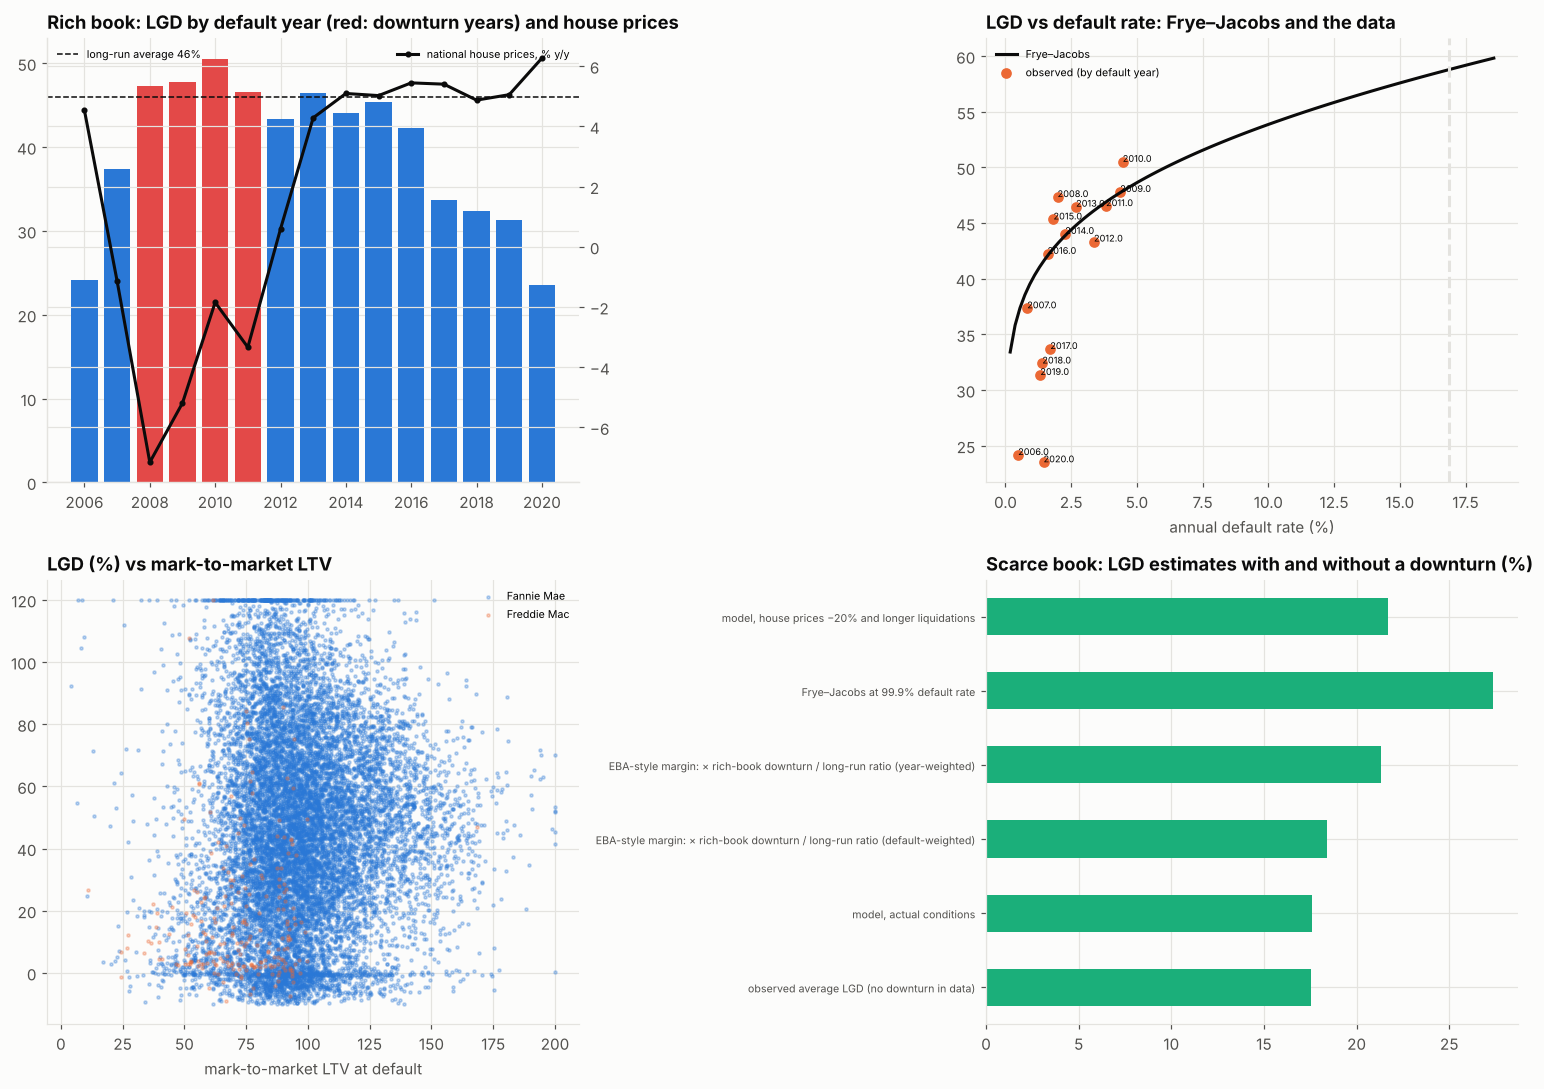

In [9]:
fig, ax = plt.subplots(2, 2, figsize=(14, 10))
a = ax[0, 0]
y = BY_YEAR[BY_YEAR["liquidations"] >= 30]
a.bar(
    y.index,
    y["mean_lgd"] * 100,
    color=[PALETTE[7] if v in DT_YEARS else PALETTE[0] for v in y.index],
)
a.axhline(
    LRA_LGD * 100,
    color=INK,
    ls="--",
    lw=1,
    label=f"long-run average {LRA_LGD:.0%}",
)
a2 = a.twinx()
a2.plot(
    macro_y.loc[y.index.min() : y.index.max()].index,
    macro_y.loc[
        y.index.min() : y.index.max(), "house prices, 4-quarter change"
    ]
    * 100,
    color=INK,
    marker="o",
    ms=3,
    label="national house prices, % y/y",
)
a.set_title(
    "Rich book: LGD by default year (red: downturn years) and house prices"
)
a.legend(fontsize=7, loc="upper left")
a2.legend(fontsize=7, loc="upper right")
a = ax[0, 1]
grid = np.linspace(
    max(dr_f.min() * 0.5, 1e-4), max(dr_f.max(), DR_999) * 1.1, 100
)
a.plot(
    grid * 100,
    frye_jacobs(grid, PD_LR, LRA_LGD) * 100,
    color=INK,
    label="Frye–Jacobs",
)
a.scatter(
    FJ["default rate"] * 100,
    FJ["mean_lgd"] * 100,
    color=PALETTE[1],
    label="observed (by default year)",
)
for yr, r in FJ.iterrows():
    a.annotate(
        str(yr), (r["default rate"] * 100, r["mean_lgd"] * 100), fontsize=6
    )
a.axvline(DR_999 * 100, color=GRID, ls="--")
a.set_xlabel("annual default rate (%)")
a.set_title("LGD vs default rate: Frye–Jacobs and the data")
a.legend(fontsize=7)
a = ax[1, 0]
for b, col in zip(BOOKS, PALETTE):
    s = LIQ[LIQ["book"] == b]
    a.scatter(
        s["mtm_ltv"].clip(0, 200),
        s["lgd"].clip(-0.1, 1.2) * 100,
        s=4,
        alpha=0.3,
        color=col,
        label=b,
    )
a.set_xlabel("mark-to-market LTV at default")
a.set_title("LGD (%) vs mark-to-market LTV")
a.legend(fontsize=7)
a = ax[1, 1]
DOWN.mul(100).plot.barh(ax=a, color=PALETTE[2])
a.set_title("Scarce book: LGD estimates with and without a downturn (%)")
a.tick_params(axis="y", labelsize=7)
fig.tight_layout()
save_fig(fig, "01_downturn_lgd")
plt.show()

In [10]:
dash = make_subplots(
    rows=2,
    cols=2,
    subplot_titles=(
        "LGD by disposition type",
        "Scarce book: cross-validated MAE by strategy",
        "Segment LGD: scarce vs rich book",
        "Months from default to liquidation by default year",
    ),
)
for b in BOOKS:
    dash.add_trace(
        go.Bar(x=BY_DISP.index, y=BY_DISP[("mean", b)] * 100, name=b), 1, 1
    )
dash.add_trace(
    go.Bar(x=TRANSFER.index, y=TRANSFER["MAE"], name="transfer MAE"), 1, 2
)
dash.add_trace(
    go.Bar(x=SHRINK.index, y=SHRINK["MAE"], name="shrinkage MAE"), 1, 2
)
sg = SEGS.dropna()
dash.add_trace(
    go.Scatter(
        x=sg["mean (rich book)"] * 100,
        y=sg["mean"] * 100,
        mode="markers",
        text=sg.index,
        marker=dict(size=np.sqrt(sg["size"]) * 3),
        name="segments",
    ),
    2,
    1,
)
for b in BOOKS:
    s = (
        LIQ[LIQ["book"] == b]
        .groupby("default_year")["months_to_liquidate"]
        .median()
    )
    dash.add_trace(go.Scatter(x=s.index, y=s.values, name=b), 2, 2)
dash.update_layout(
    height=950,
    width=1400,
    template="simple_white",
    barmode="group",
    title=(
        "Downturn LGD with scarce recoveries: Fannie Mae 2005–2008 vs Freddie"
        " Mac 2018–2023"
    ),
)
save_dashboard(dash, "dashboard")
dash.show()

Dashboard saved: outputs/dashboard.html and .png


## 10. Reading the results and limitations

**Two books, two worlds.**

| Book | Liquidations | Mean LGD | Balance-weighted LGD | Liquidation dates |
|---|---|---|---|---|
| Fannie Mae 2005–2008 (rich) | 13,300 | 46.0% | 41.9% | 2005–2025 |
| Freddie Mac 2018–2023 (scarce) | 222 | 17.6% | 14.1% | 2019–2025 |

LGD depends heavily on how the loan ends. REO dispositions lose the most (50% in the rich book, 26% in the scarce one), then note sales, short sales and third-party sales. In the scarce book, loans defaulted with an average mark-to-market LTV far below that of the crisis loans, because house prices kept rising after origination.

**The downturn is in the data, and the default-weighted average already contains it.**
- **Downturn years:** national house prices fell and unemployment was above its median in 2008–2011, the years with 66% of the rich book's liquidations.
- **Three ways to average:**
  - LGD of loans that defaulted in those years: 48.2%;
  - default-weighted long-run average required by the EBA: 46.0%;
  - average of annual LGDs, each year weighted equally: 39.7%.
- **Annual LGD** rose from 24% for 2006 defaults to a peak of 51% for 2010 defaults, stayed above 42% until 2016, then fell to 16–27% for 2020–2023 defaults, as mark-to-market LTVs fell to around 50.

When a portfolio's defaults are concentrated in a crisis, the default-weighted long-run LGD is close to downturn LGD, and the "downturn add-on" looks small (+5%). Against a year-weighted average it is +21%.

**Frye–Jacobs fits the crisis, not the recovery.** With the rich book's long-run PD (1.9%), its long-run LGD and Basel's 15% correlation:
- **Crisis and aftermath:** the function tracks annual LGD closely from 2009 to 2016 (errors of 0–3 points). The correlation between annual LGD and default rate is 0.75.
- **The tails:** it misses at both ends. It overstates LGD for the low-default years 2017–2020 (41–42% against 24–34%), because it ties LGD only to the default rate and not to house prices, which had recovered. It understates the onset of the crisis in 2006.
- **At the 99.9% default rate** (16.9%) it implies a downturn LGD of 58.8%, ten points above anything observed. That is a conservative but not absurd number for a far worse crisis than 2008.

**Scarce data: shrinkage and transfer help, modestly.** On the scarce book's 222 liquidations (16 segments, a median of 13 each), cross-validated mean absolute errors were:
- pooled mean 0.156;
- segment averages 0.147;
- shrinkage to the pooled mean 0.148;
- shrinkage toward rich-book segment means rescaled to the scarce book's level 0.144.

Transfer learning did better:

| Strategy | MAE | Mean bias |
|---|---|---|
| Fractional logit trained on the rich book, recalibrated on the scarce book | 0.138 | 0.000 |
| LightGBM, recalibrated | 0.139 | 0.001 |
| LightGBM pooled, scarce data weighted ×50 | 0.140 | 0.005 |
| Fractional logit, scarce book only | 0.146 | 0.000 |
| LightGBM, rich book only | 0.155 | +0.054 |
| Fractional logit, rich book only | 0.165 | +0.073 |

- **Source only:** the rich-book models applied unchanged overstate the scarce book's LGD by 5–7 points. The relation between LTV and loss changed after 2008: servicing reforms, faster liquidations and more mortgage insurance.
- **Recalibration:** re-estimating only the intercept and slope of the source model on the scarce data keeps the source's shape, learned from 13,000 liquidations, and fixes its level with two parameters. It gave the lowest error and no bias.
- **Out of time on the rich book:** trained on defaults before 2015 and tested on later ones, LightGBM (MAE 0.197) and the fractional logit (0.212) beat the pre-2015 average (0.270). The pre-2015 average overstated post-2015 LGD by ten points.

**A downturn LGD for a book that has never seen one.**

| Approach | Scarce book LGD |
|---|---|
| Observed average (no downturn in the data) | 17.6% |
| EBA-style margin, default-weighted ratio from the rich book | 18.4% |
| EBA-style margin, year-weighted ratio | 21.3% |
| Recalibrated model, house prices −20% and crisis liquidation times | 21.7% |
| Frye–Jacobs at the 99.9% default rate | 27.3% |

The approaches span 18–27%, a factor of 1.5 for the same book.
- **Model-based stress:** applying a 2008-style fall in house prices through the recalibrated model raises LGD by four points, because today's defaulted loans start with low LTVs and much equity is left even after a 20% fall.
- **Frye–Jacobs:** it gives the most conservative figure because it scales with the default rate, not with collateral.
- **EBA-style margin:** a margin borrowed from another portfolio's downturn depends on how its long-run average is weighted.

**What this means for LGD modelling and validation.**
- **Data-poor portfolios:** transfer learning with recalibration is a practical way to use crisis data from a related portfolio; using the old model unchanged overstates losses when underwriting and servicing have changed.
- **Shrinkage:** segment LGDs on a few dozen observations should be shrunk, and an informed prior from a richer portfolio helps more than the pooled mean.
- **Downturn LGD without a downturn in the data:** the key driver for mortgages is the collateral path, so a model that links LGD to mark-to-market LTV and stresses house prices is more transparent than a ratio borrowed from elsewhere. Frye–Jacobs is a useful conservative benchmark.
- **Weighting the long-run average:** the choice can move the downturn add-on by a factor of four; validators should report both.

**Limitations.**
- **Data:** sample files of 50,000 loans per vintage; Fannie Mae's converted files report losses without the breakdown of proceeds and expenses. Losses are those reported at disposition; later recoveries and mortgage-insurance claims may be missing. LGD outside −10% to 150% was dropped.
- **Mark-to-market LTV:** state indices, not property-level values; the default date is the last paid instalment plus three months.
- **Scarce book:** 222 liquidations, mostly from the pandemic and post-pandemic years with strong house prices and forbearance; its long-run PD (0.7%) covers no full cycle.
- **Frye–Jacobs:** uses Basel's 15% correlation, not one estimated for these books; the stress scenario applies a uniform 20% fall to every state.

In [11]:
SUMMARY.to_csv(OUT_DIR / "liquidations_summary.csv")
BY_YEAR.to_csv(OUT_DIR / "rich_book_lgd_by_default_year.csv")
BY_DISP.to_csv(OUT_DIR / "lgd_by_disposition.csv")
FJ.to_csv(OUT_DIR / "frye_jacobs_vs_observed.csv")
FJ_SUM.to_csv(OUT_DIR / "frye_jacobs_summary.csv")
SEGS.to_csv(OUT_DIR / "segments.csv")
SHRINK.to_csv(OUT_DIR / "shrinkage_cv.csv")
TRANSFER.to_csv(OUT_DIR / "transfer_learning_cv.csv")
DOWN.to_csv(OUT_DIR / "scarce_book_downturn_lgd.csv")
pd.DataFrame(CHECK).T.to_csv(OUT_DIR / "rich_book_out_of_time_check.csv")
print("Outputs written:", ", ".join(sorted(p.name for p in OUT_DIR.iterdir())))

Outputs written: 01_downturn_lgd.png, dashboard.html, dashboard.png, frye_jacobs_summary.csv, frye_jacobs_vs_observed.csv, lgd_by_disposition.csv, liquidations_summary.csv, rich_book_lgd_by_default_year.csv, rich_book_out_of_time_check.csv, scarce_book_downturn_lgd.csv, segments.csv, shrinkage_cv.csv, transfer_learning_cv.csv


## References

### Downturn LGD and regulation

- European Banking Authority. (2019). *Guidelines for the estimation of LGD appropriate for an economic downturn ('downturn LGD estimation')* (EBA/GL/2019/03). https://eba.europa.eu/eba-publishes-final-guidelines-on-the-estimation-of-lgd-under-an-economic-downturn
- Frye, J., & Jacobs, M. (2012). Credit loss and systematic loss given default. *The Journal of Credit Risk, 8*(1), 109–140. https://doi.org/10.21314/JCR.2012.138
- Altman, E. I., Brady, B., Resti, A., & Sironi, A. (2005). The link between default and recovery rates: Theory, empirical evidence, and implications. *The Journal of Business, 78*(6), 2203–2228. https://doi.org/10.1086/497044
- Qi, M., & Yang, X. (2009). Loss given default of high loan-to-value residential mortgages. *Journal of Banking & Finance, 33*(5), 788–799. https://doi.org/10.1016/j.jbankfin.2008.09.010

### Methods

- Papke, L. E., & Wooldridge, J. M. (1996). Econometric methods for fractional response variables with an application to 401(k) plan participation rates. *Journal of Applied Econometrics, 11*(6), 619–632. https://doi.org/10.1002/(SICI)1099-1255(199611)11:6<619::AID-JAE418>3.0.CO;2-1
- Pan, S. J., & Yang, Q. (2010). A survey on transfer learning. *IEEE Transactions on Knowledge and Data Engineering, 22*(10), 1345–1359. https://doi.org/10.1109/TKDE.2009.191
- Ke, G., Meng, Q., Finley, T., Wang, T., Chen, W., Ma, W., Ye, Q., & Liu, T.-Y. (2017). LightGBM: A highly efficient gradient boosting decision tree. *Advances in Neural Information Processing Systems, 30*. https://proceedings.neurips.cc/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html

### Data

- Fannie Mae. (2026). *Single-Family Loan Performance Data* [Data set]. https://capitalmarkets.fanniemae.com/credit-risk-transfer/single-family-credit-risk-transfer/fannie-mae-single-family-loan-performance-data
- Freddie Mac. (2026). *Single-Family Loan-Level Dataset* [Data set]. https://www.freddiemac.com/research/datasets/sf-loanlevel-dataset
- Federal Housing Finance Agency and U.S. Bureau of Labor Statistics. (2026). *State and national house price indexes; unemployment rate* [Data sets]. Federal Reserve Bank of St. Louis (FRED). https://fred.stlouisfed.org/